# Attribution results: how three small LLMs read an initial value problem

**Test split, 2026-11-06.** Final summary of the attribution step of the thesis, for three models:
**Qwen3-4B-Instruct-2507**, **Qwen2.5-Math-1.5B-Instruct** and **Phi-4-mini-instruct**.

**Question.** When a model solves an over-specified IVP (an ODE, the conditions that fix the solution, and one
uninformative *distractor* condition), which parts of the problem does its answer depend on? Does it stay away
from the distractor?

**Two targets** (what is being explained):
- **(a), main:** log p of the model's **own final answer**, teacher-forced on its own step-by-step working.
  It explains what the model actually did, wrong answers included.
- **(c), control:** log p of the **true solution** right after the problem, with no working. The same target for
  every model, so models and items compare directly.

**Methods** (gradient and attention only; perturbation methods such as LIME, SHAP and occlusion are excluded,
because any change to an ODE problem makes it a different problem):
- **Gradient×Input**: how much the answer's log p changes with each input token, at the real input.
- **Attention**: how much the answer tokens attend to each prompt field (mean over heads and layers).
- **Attention rollout**: attention propagated through the layers. It has a known early-token bias, so it is
  weak evidence.
- Integrated Gradients was computed but is **not used for conclusions** (see the appendix).

**How to read the numbers.** *Density* = a field's share of the attribution ÷ its share of the prompt tokens.
1× means "in proportion to its length", 2× means twice as much. Every comparison is computed **per item** and
summarised as the **median with a bootstrap 95% CI** (2000 resamples). An interval that doesn't contain 1× is a
clear effect.

The numbers in this notebook are computed from `results/attribution/`; the written summary is in
`ATTRIBUTION_FINDINGS.md`.

In [1]:
import glob, json, math, os, sys
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display

ROOT = os.path.abspath('.')
sys.path.insert(0, ROOT)
import attribution_plots as AP

FIG = os.path.join('figures', 'attribution', 'summary_notebook')
os.makedirs(FIG, exist_ok=True)
plt = AP.setup_mpl()
pd.set_option('display.max_colwidth', None)

# the newest finished, usable run per model and target
runs = {}
for d in sorted(glob.glob(os.path.join('results', 'attribution', '2026*'))):
    if not os.path.exists(os.path.join(d, 'meta.json')):
        continue
    r = AP.load_run(d)
    if r['usable']:
        runs[(r['model'], r['target'])] = r
RUNS = list(runs.values())
MODELS = AP.models_present(RUNS)
ML = AP.MODEL_LABEL
MAIN = AP.MAIN

def fmt(s, log2=False):
    if s is None:
        return '–'
    f = (lambda v: 2 ** v) if log2 else (lambda v: v)
    return f"{f(s['median']):.2f} [{f(s['lo']):.2f}, {f(s['hi']):.2f}]"

def show(name, width=None):
    display(Image(filename=os.path.join(FIG, name), width=width))

pd.DataFrame([{'model': ML[r['model']], 'target': r['target'], 'items': len(r['rows']),
               'dtype': r['meta']['dtype'], 'GPU hours': round(r['meta']['seconds'] / 3600, 1),
               'run folder': os.path.basename(r['dir'])}
              for r in sorted(RUNS, key=lambda r: (AP.MODEL_ORDER.index(r['model']), r['target']))])

,model,target,items,dtype,GPU hours,run folder
0,Qwen3-4B,a,129,float16,4.4,20261104T103549Z_qwen3-4b-instruct-2507_a_test
1,Qwen3-4B,c,144,float16,2.0,20261104T083417Z_qwen3-4b-instruct-2507_c_test
2,Qwen2.5-Math-1.5B,a,143,float32,5.9,20261104T185912Z_qwen2.5-math-1.5b-instruct_a_test
3,Qwen2.5-Math-1.5B,c,144,float32,4.1,20261104T185912Z_qwen2.5-math-1.5b-instruct_c_test
4,Phi-4-mini,a,143,float16,3.6,20261104T130748Z_phi-4-mini-instruct_a_test
5,Phi-4-mini,c,144,float16,2.2,20261104T092536Z_phi-4-mini-instruct_c_test


## 1. Headline results
The two clearest results, side by side for all three models. Left: does the **distractor** get less than the
conditions that determine the answer? Right: in `duplicate` items, where the same condition is written twice,
does the **second copy** get less than the first? Left of 1× = less.

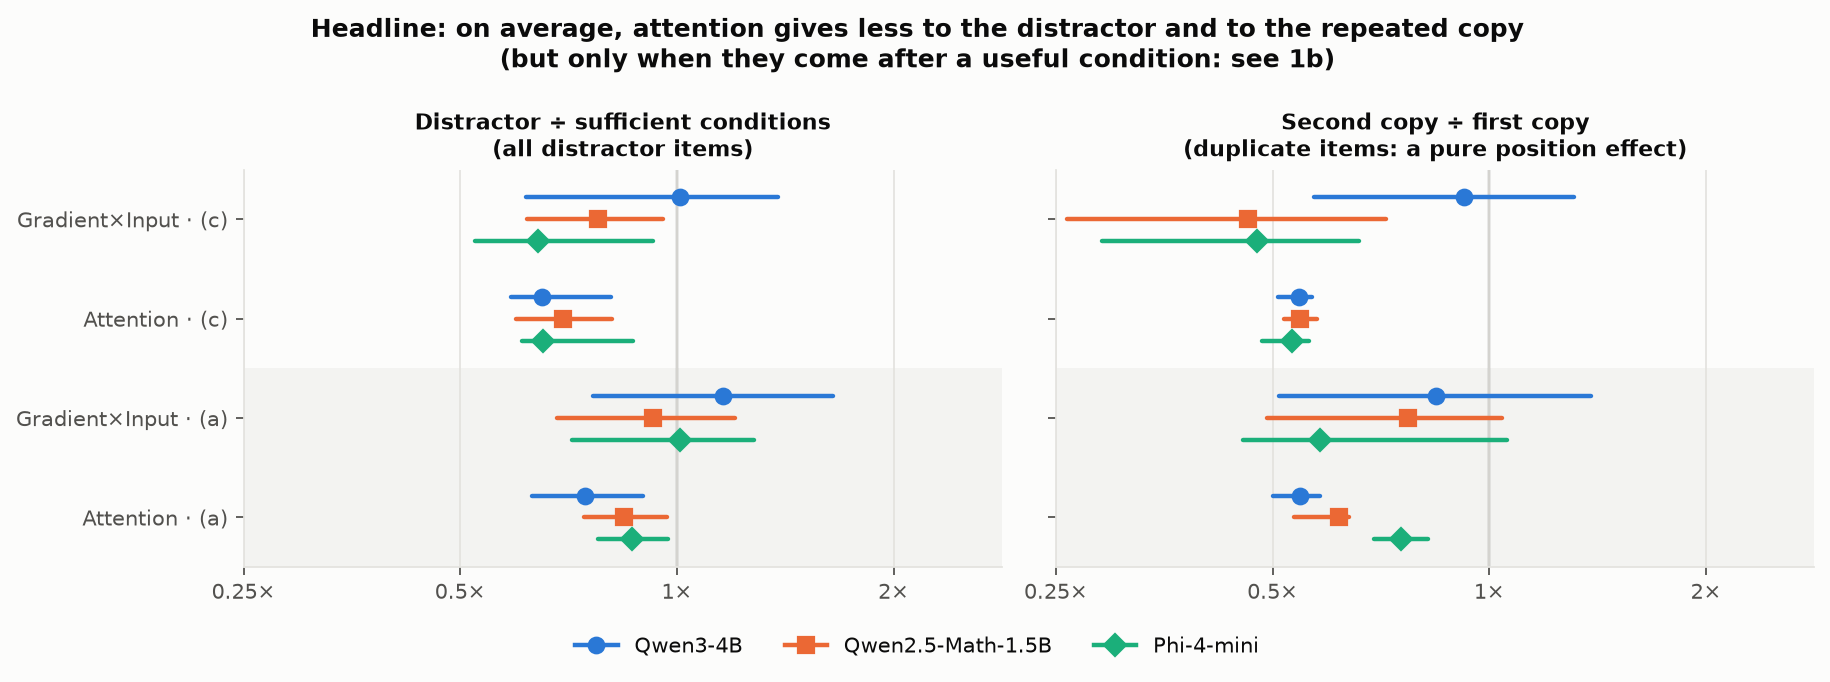

model                                                             Qwen3-4B  \
measure                            method · target                           
Distractor ÷ sufficient conditions Gradient×Input · (c)  1.01 [0.62, 1.38]   
                                   Attention · (c)       0.65 [0.59, 0.81]   
                                   Gradient×Input · (a)  1.16 [0.76, 1.65]   
                                   Attention · (a)       0.74 [0.63, 0.90]   
Second copy ÷ first copy           Gradient×Input · (c)  0.92 [0.57, 1.31]   
                                   Attention · (c)       0.54 [0.51, 0.57]   
                                   Gradient×Input · (a)  0.84 [0.51, 1.38]   
                                   Attention · (a)       0.55 [0.50, 0.58]   

model                                                    Qwen2.5-Math-1.5B  \
measure                            method · target                           
Distractor ÷ sufficient conditions Gradient×Input · (c)  0.78 [0.62, 0.96]   
                                   Attention · (c)       0.69 [0.60, 0.81]   
                                   Gradient×Input · (a)  0.93 [0.68, 1.20]   
                                   Attention · (a)       0.84 [0.74, 0.97]   
Second copy ÷ first copy           Gradient×Input · (c)  0.46 [0.26, 0.72]   
                                   Attention · (c)       0.55 [0.52, 0.58]   
                                   Gradient×Input · (a)  0.77 [0.49, 1.04]   
                                   Attention · (a)       0.62 [0.54, 0.64]   

model                                                           Phi-4-mini  
measure                            method · target                          
Distractor ÷ sufficient conditions Gradient×Input · (c)  0.64 [0.52, 0.93]  
                                   Attention · (c)       0.65 [0.61, 0.87]  
                                   Gradient×Input · (a)  1.01 [0.71, 1.28]  
                                   Attention · (a)       0.87 [0.78, 0.97]  
Second copy ÷ first copy           Gradient×Input · (c)  0.48 [0.29, 0.66]  
                                   Attention · (c)       0.53 [0.48, 0.56]  
                                   Gradient×Input · (a)  0.58 [0.45, 1.06]  
                                   Attention · (a)       0.75 [0.69, 0.82]

In [2]:
from matplotlib.lines import Line2D
rows = [('gxi', 'c'), ('attn', 'c'), ('gxi', 'a'), ('attn', 'a')]
rlab = {('gxi', 'c'): 'Gradient×Input · (c)', ('attn', 'c'): 'Attention · (c)',
        ('gxi', 'a'): 'Gradient×Input · (a)', ('attn', 'a'): 'Attention · (a)'}
panels = [('distr_log2', lambda r: r['subtype'] != 'none', 'Distractor ÷ sufficient conditions\n(all distractor items)'),
          ('dup_log2', lambda r: r['subtype'] == 'duplicate', 'Second copy ÷ first copy\n(duplicate items: a pure position effect)')]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
headline = []
for ax, (key, sel, title) in zip(axes, panels):
    for i, (meth, t) in enumerate(rows):
        for j, mk in enumerate(MODELS):
            run = runs.get((mk, t))
            if run is None:
                continue
            s = AP.med_ci([x.get(key) for x in run['per'][meth] if sel(x['_row'])])
            headline.append({'measure': title.split('\n')[0], 'method · target': rlab[(meth, t)],
                             'model': ML[mk], 'median [95% CI]': fmt(s, log2=True)})
            y = i + (j - 1) * 0.22
            c = AP.MODEL_COLOR[mk]
            ax.plot([s['lo'], s['hi']], [y, y], color=c, lw=2, solid_capstyle='round')
            ax.plot(s['median'], y, AP.MODEL_MARKER[mk], ms=7, color=c)
    ax.axhspan(1.5, 3.5, color=AP.GRID, alpha=0.35, lw=0, zorder=0)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([rlab[r] for r in rows])
    ax.set_ylim(len(rows) - 0.5, -0.5)
    ax.grid(axis='y', visible=False)
    AP.ratio_axis(ax, -2, 1.5)
    ax.set_title(title, fontsize=10)
fig.legend(handles=[Line2D([], [], color=AP.MODEL_COLOR[m], marker=AP.MODEL_MARKER[m], ms=7, lw=2, label=ML[m])
                    for m in MODELS], loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Headline: on average, attention gives less to the distractor and to the repeated copy\n'
             '(but only when they come after a useful condition: see 1b)', fontweight='bold')
fig.tight_layout()
fig.savefig(os.path.join(FIG, '0_headline.png'), dpi=160, bbox_inches='tight')
plt.close(fig)
show('0_headline.png')
pd.DataFrame(headline).pivot_table(index=['measure', 'method · target'], columns='model', values='median [95% CI]',
                                   aggfunc='first', sort=False)[[ML[m] for m in MODELS]]

**Reading.**
- **Attention** to the distractor is about a third lower than to the useful conditions in target (c), in all three
  models, and still lower in (a). The second copy of a repeated condition gets about **half** the attention of the
  first. Both results are consistent across models, with tight intervals.
- **Gradient×Input** agrees only partly. In (c), Qwen2.5-Math and Phi also *depend* less on the distractor and on
  the second copy; Qwen3-4B doesn't. In (a), after the model's own working, no model shows it clearly.
- So **"looked at less" and "matters less for the answer" don't always coincide**. This is the main open question
  passed to the representation analysis.
- **These are averages over two very different cases.** Section 1b splits them by the distractor's order: the
  discount happens only when the distractor comes after a useful condition.

In [3]:
# all figures 1-9 from the shared plotting module (the same code runs in the Kaggle notebooks)
stats = {'runs': {}}
for f in (AP.fig_field_density, AP.fig_distractor, AP.fig_duplicate, AP.fig_layers, AP.fig_working,
          AP.fig_correct_wrong, AP.fig_order, AP.fig_ig, AP.fig_ig_baselines):
    f(plt, RUNS, FIG, stats)
json.dump(stats, open(os.path.join(FIG, 'stats.json'), 'w', encoding='utf-8'), indent=1)
print('figures written to', FIG)

figures written to figures\attribution\summary_notebook


## 1b. The distractor is discounted only when it comes after a useful condition
The same ratio as in the headline (per token, distractor ÷ useful condition), split by **where the distractor is
written** among the conditions. `rescaled` and `unrelated` items only (in `duplicate` items the distractor is a copy
of a useful condition, see section 4). The test split has the distractor first in about half of these items.

**Control row:** items with no distractor and two useful conditions (second-order ODEs), condition 2 ÷ condition 1.
If later conditions simply got less attention, this row would be below 1× too.

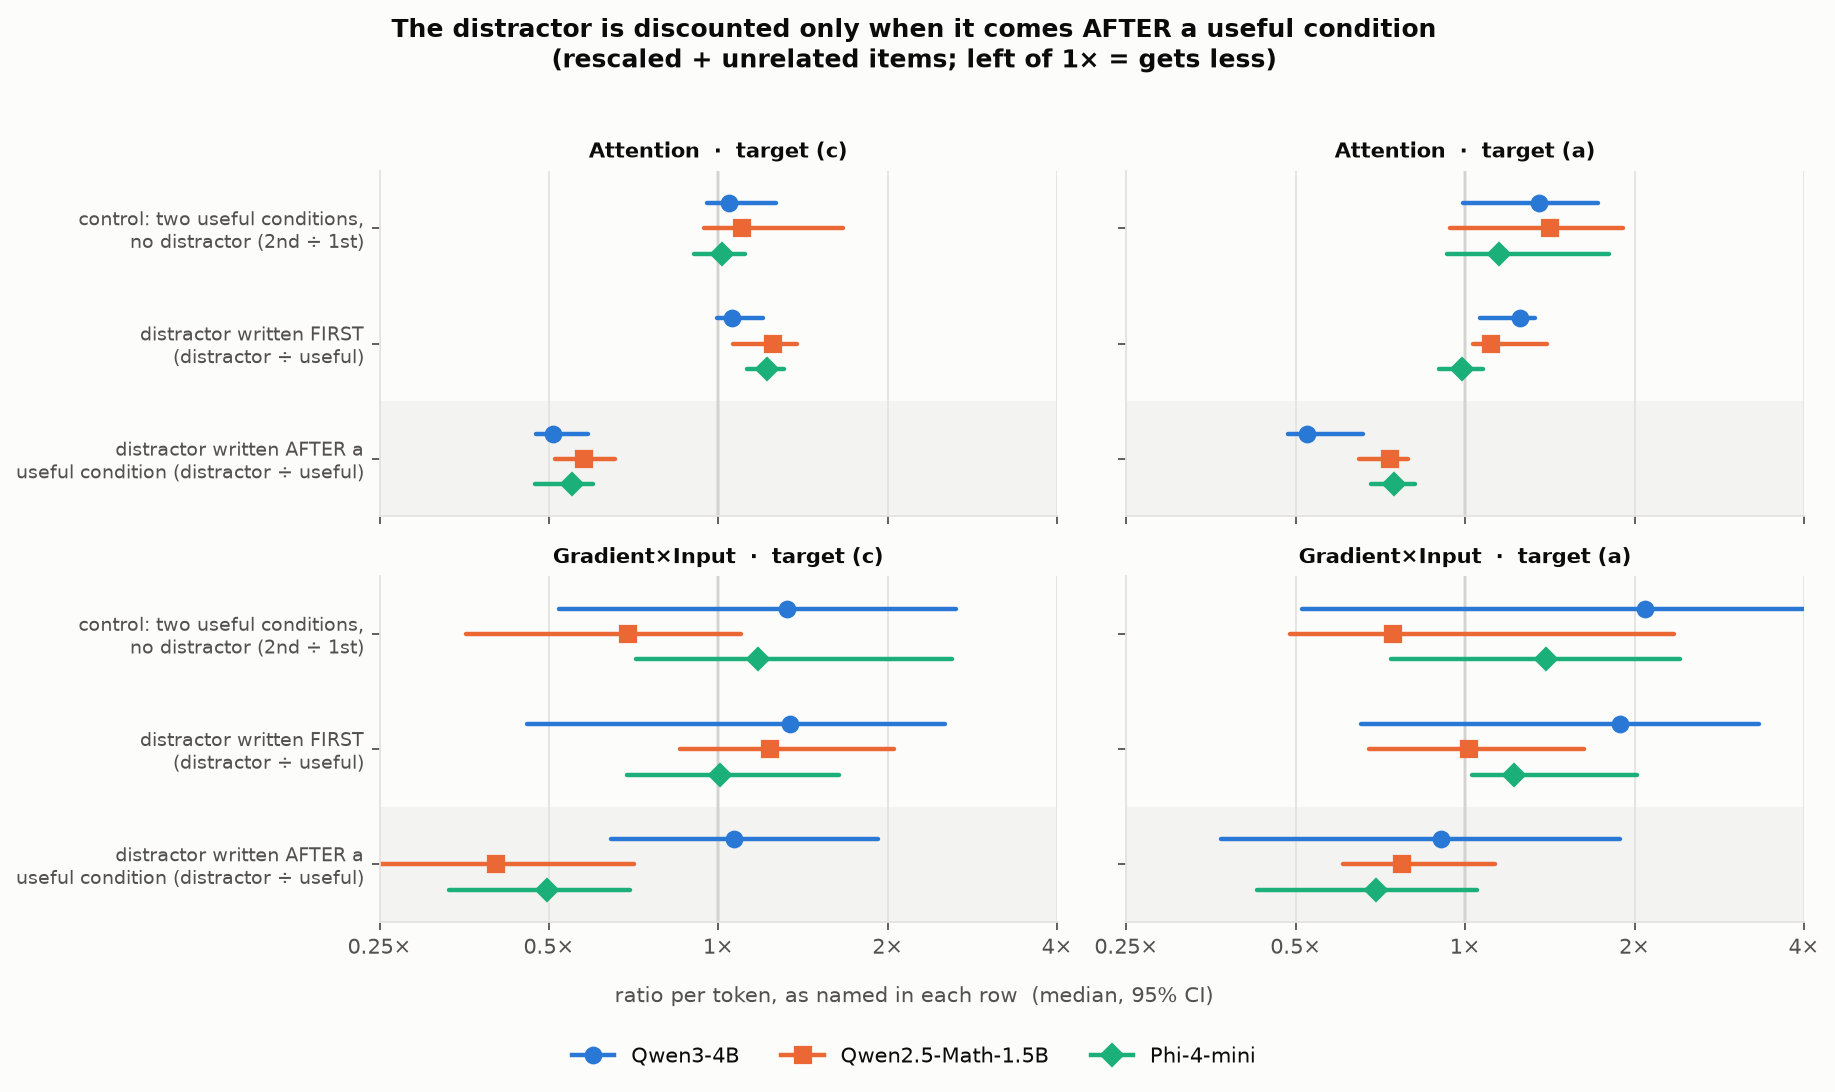

n  \
target method         case                                                                    
c      Attention      control: two useful conditions, no distractor (2nd ÷ 1st)          18   
                      distractor written FIRST (distractor ÷ useful)                     30   
                      distractor written AFTER a useful condition (distractor ÷ useful)  42   
       Gradient×Input control: two useful conditions, no distractor (2nd ÷ 1st)          18   
                      distractor written FIRST (distractor ÷ useful)                     29   
                      distractor written AFTER a useful condition (distractor ÷ useful)  41   
a      Attention      control: two useful conditions, no distractor (2nd ÷ 1st)          16   
                      distractor written FIRST (distractor ÷ useful)                     24   
                      distractor written AFTER a useful condition (distractor ÷ useful)  35   
       Gradient×Input control: two useful conditions, no distractor (2nd ÷ 1st)          14   
                      distractor written FIRST (distractor ÷ useful)                     16   
                      distractor written AFTER a useful condition (distractor ÷ useful)  31   

                                                                                                  Qwen3-4B  \
target method         case                                                                                   
c      Attention      control: two useful conditions, no distractor (2nd ÷ 1st)          1.05 [0.95, 1.27]   
                      distractor written FIRST (distractor ÷ useful)                     1.06 [0.99, 1.20]   
                      distractor written AFTER a useful condition (distractor ÷ useful)  0.51 [0.47, 0.59]   
       Gradient×Input control: two useful conditions, no distractor (2nd ÷ 1st)          1.33 [0.52, 2.64]   
                      distractor written FIRST (distractor ÷ useful)                     1.34 [0.46, 2.53]   
                      distractor written AFTER a useful condition (distractor ÷ useful)  1.07 [0.65, 1.92]   
a      Attention      control: two useful conditions, no distractor (2nd ÷ 1st)          1.35 [0.99, 1.72]   
                      distractor written FIRST (distractor ÷ useful)                     1.25 [1.06, 1.33]   
                      distractor written AFTER a useful condition (distractor ÷ useful)  0.52 [0.48, 0.66]   
       Gradient×Input control: two useful conditions, no distractor (2nd ÷ 1st)          2.09 [0.51, 5.04]   
                      distractor written FIRST (distractor ÷ useful)                     1.88 [0.65, 3.33]   
                      distractor written AFTER a useful condition (distractor ÷ useful)  0.91 [0.37, 1.89]   

                                                                                         Qwen2.5-Math-1.5B  \
target method         case                                                                                   
c      Attention      control: two useful conditions, no distractor (2nd ÷ 1st)          1.10 [0.94, 1.67]   
                      distractor written FIRST (distractor ÷ useful)                     1.25 [1.06, 1.38]   
                      distractor written AFTER a useful condition (distractor ÷ useful)  0.58 [0.51, 0.66]   
       Gradient×Input control: two useful conditions, no distractor (2nd ÷ 1st)          0.69 [0.36, 1.10]   
                      distractor written FIRST (distractor ÷ useful)                     1.24 [0.85, 2.05]   
                      distractor written AFTER a useful condition (distractor ÷ useful)  0.40 [0.23, 0.71]   
a      Attention      control: two useful conditions, no distractor (2nd ÷ 1st)          1.41 [0.94, 1.91]   
                      distractor written FIRST (distractor ÷ useful)                     1.11 [1.03, 1.40]   
                      distractor written AFTER a useful condition (distractor ÷ useful)  0.74 [0.65, 0.79]   
       G

In [4]:
show('9_distractor_order.png', width=950)
lab = dict(AP.ORDER_ROWS)
tab = []
for t in ('c', 'a'):
    for meth in ('attn', 'gxi'):
        for key, _ in AP.ORDER_ROWS:
            k0 = f'{t} | order {key} | {MODELS[0]} | {meth}'
            tab.append({'target': t, 'method': AP.METHOD_LABEL[meth], 'case': lab[key].replace('\n', ' '),
                        'n': stats[k0]['n'] if k0 in stats else '–',
                        **{ML[mk]: fmt(stats.get(f'{t} | order {key} | {mk} | {meth}'), log2=True) for mk in MODELS}})
pd.DataFrame(tab).set_index(['target', 'method', 'case'])

**Reading.**
- **Distractor first:** it gets **as much attention as the useful condition, or more** (about 1.0–1.3×), in every
  model and both targets (0.99–1.25×).
- **Distractor after a useful condition:** it gets about **half** (0.51–0.58× in target (c), 0.52–0.75× in (a)).
- **Control:** with two useful conditions, the second gets about the same as the first (≈ 1.0× in target (c)). So
  this is **not** a simple "later conditions get less" effect (in (a) the second useful condition even gets a
  little more, 1.15–1.41×). The groups are small (30 and 42 items in (c)), but the intervals are tight.
- Gradient×Input shows the same split for Qwen2.5-Math and Phi in target (c); Qwen3-4B shows neither.
- **What it suggests:** the models discount a condition that is **redundant or irrelevant given what they have
  already read**, not a condition that is irrelevant in itself. Even a condition on z written first isn't
  discounted. A plausible mechanism is causal attention: each token is encoded using only the tokens before it, so
  a distractor written first is encoded before any useful condition has been seen, and its hidden state can't mark
  it as redundant. The `duplicate` result (second copy ≈ 0.5×, section 4) fits the same pattern.
- **Prediction for the probes:** the distractor should be linearly separable from useful conditions in the hidden
  states only when it comes after one.

## 2. Where the attribution goes
Median density of each prompt field. Red = more than its length share, blue = less.

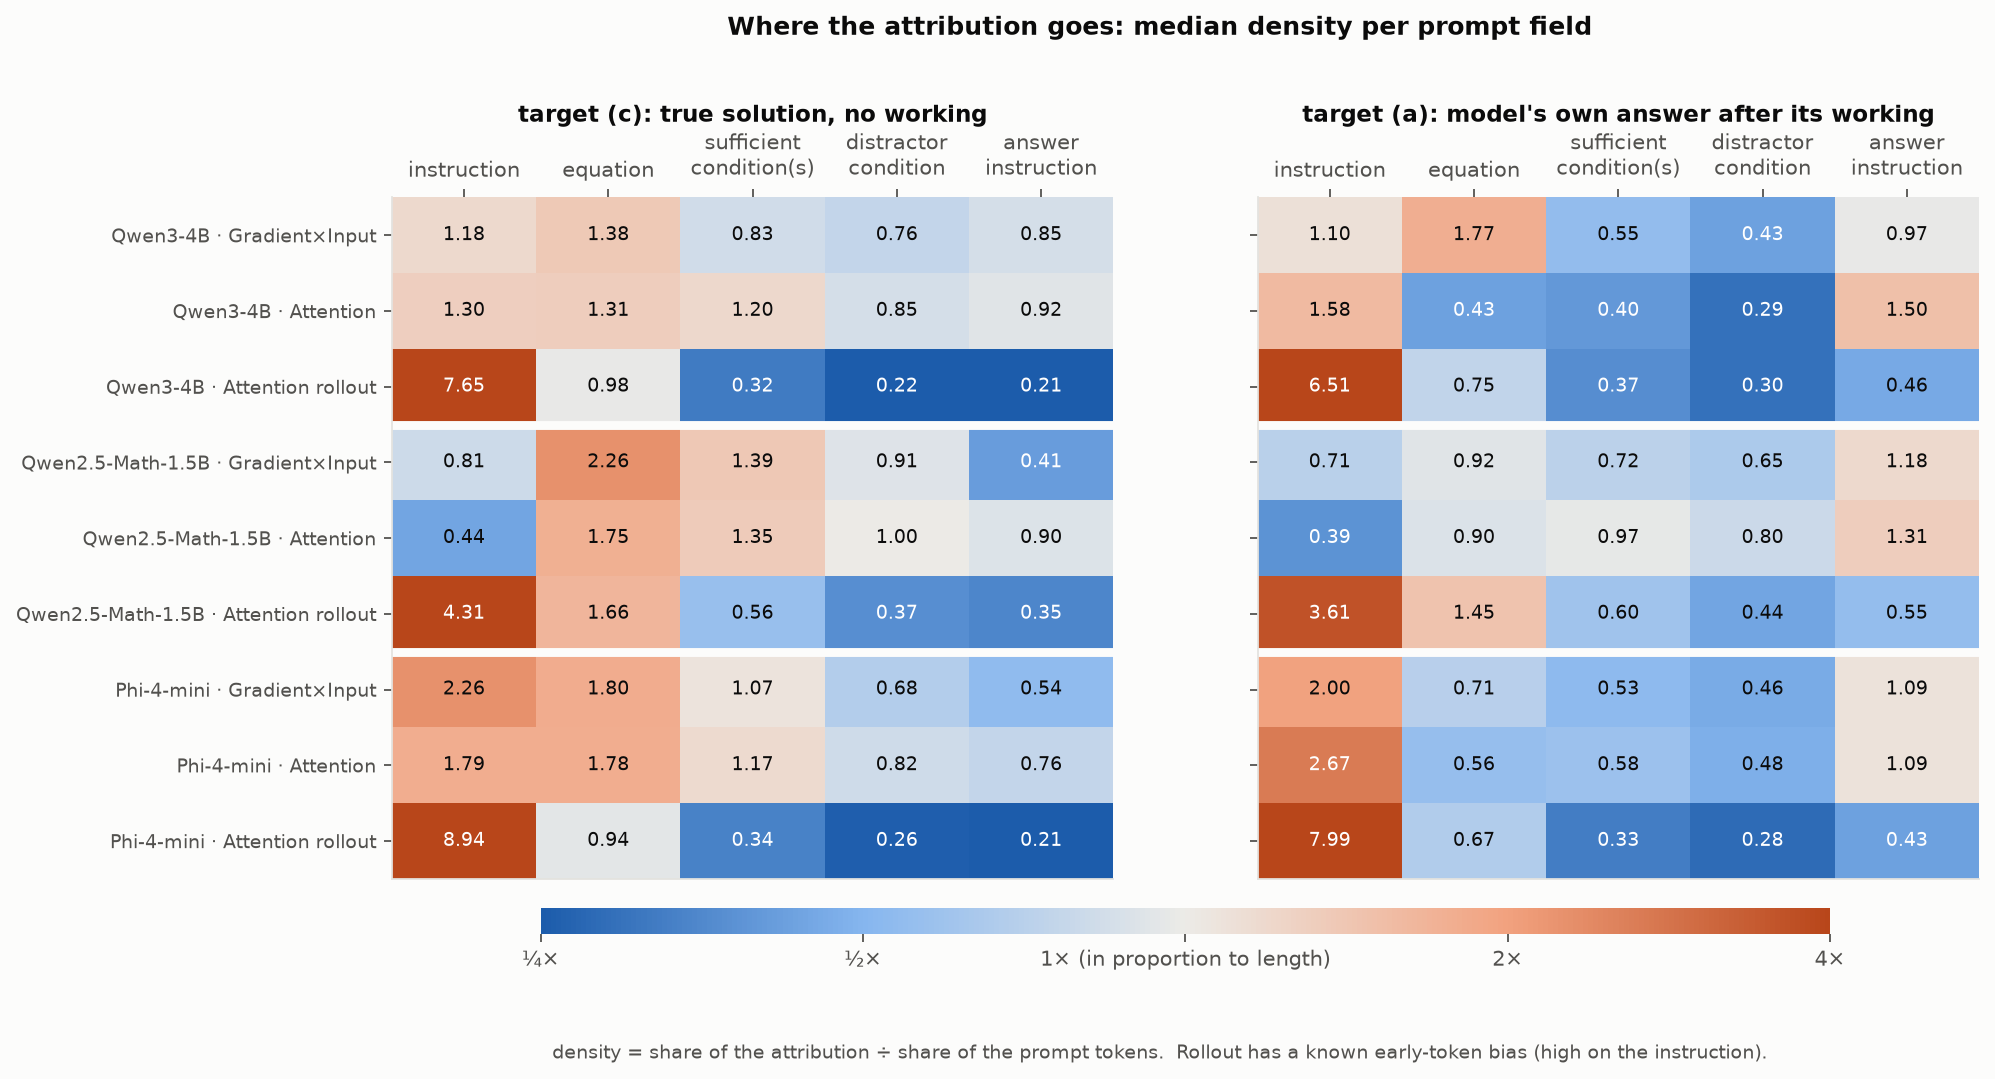

instruction  \
target model             method                                 
c      Qwen3-4B          Gradient×Input     1.18 [0.99, 1.50]   
                         Attention          1.30 [1.28, 1.32]   
                         Attention rollout  7.65 [7.39, 7.95]   
       Qwen2.5-Math-1.5B Gradient×Input     0.81 [0.71, 0.94]   
                         Attention          0.44 [0.43, 0.45]   
                         Attention rollout  4.31 [4.25, 4.39]   
       Phi-4-mini        Gradient×Input     2.26 [2.03, 2.59]   
                         Attention          1.79 [1.74, 1.88]   
                         Attention rollout  8.94 [8.62, 9.26]   
a      Qwen3-4B          Gradient×Input     1.10 [0.91, 1.42]   
                         Attention          1.58 [1.52, 1.64]   
                         Attention rollout  6.51 [6.31, 6.78]   
       Qwen2.5-Math-1.5B Gradient×Input     0.71 [0.59, 0.84]   
                         Attention          0.39 [0.38, 0.40]   
                         Attention rollout  3.61 [3.51, 3.68]   
       Phi-4-mini        Gradient×Input     2.00 [1.78, 2.31]   
                         Attention          2.67 [2.55, 2.76]   
                         Attention rollout  7.99 [7.74, 8.28]   

                                                     equation  \
target model             method                                 
c      Qwen3-4B          Gradient×Input     1.38 [1.08, 1.91]   
                         Attention          1.31 [1.27, 1.43]   
                         Attention rollout  0.98 [0.95, 1.01]   
       Qwen2.5-Math-1.5B Gradient×Input     2.26 [1.84, 2.69]   
                         Attention          1.75 [1.60, 1.90]   
                         Attention rollout  1.66 [1.64, 1.72]   
       Phi-4-mini        Gradient×Input     1.80 [1.60, 2.23]   
                         Attention          1.78 [1.65, 1.84]   
                         Attention rollout  0.94 [0.91, 0.97]   
a      Qwen3-4B          Gradient×Input     1.77 [1.27, 2.02]   
                         Attention          0.43 [0.39, 0.48]   
                         Attention rollout  0.75 [0.72, 0.78]   
       Qwen2.5-Math-1.5B Gradient×Input     0.92 [0.77, 1.21]   
                         Attention          0.90 [0.85, 1.04]   
                         Attention rollout  1.45 [1.40, 1.49]   
       Phi-4-mini        Gradient×Input     0.71 [0.54, 0.95]   
                         Attention          0.56 [0.50, 0.62]   
                         Attention rollout  0.67 [0.65, 0.69]   

                                                   sufficient  \
target model             method                                 
c      Qwen3-4B          Gradient×Input     0.83 [0.70, 0.98]   
                         Attention          1.20 [1.14, 1.29]   
                         Attention rollout  0.32 [0.31, 0.34]   
       Qwen2.5-Math-1.5B Gradient×Input     1.39 [1.13, 1.58]   
                         Attention          1.35 [1.26, 1.41]   
                         Attention rollout  0.56 [0.53, 0.59]   
       Phi-4-mini        Gradient×Input     1.07 [0.91, 1.20]   
                         Attention          1.17 [1.12, 1.26]   
                         Attention rollout  0.34 [0.32, 0.36]   
a      Qwen3-4B          Gradient×Input     0.55 [0.47, 0.67]   
                         Attention          0.40 [0.37, 0.43]   
                         Attention rollout  0.37 [0.36, 0.38]   
       Qwen2.5-Math-1.5B Gradient×Input     0.72 [0.61, 0.92]   
                         Attention          0.97 [0.90, 1.02]   
                         Attention rollout  0.60 [0.58, 0.63]   
       Phi-4-mini        Gradient×Input     0.53 [0.45, 0.60]   
                         Attention          0.58 [0.55, 0.63]   
                         Attention rollout  0.33 [0.30, 0.35]   

                                                   distractor  \
target model             method                                 
c      Qwen3-4B  

In [5]:
show('1_field_density.png')
tab = []
for t in ('c', 'a'):
    for mk in MODELS:
        for meth in MAIN:
            tab.append({'target': t, 'model': ML[mk], 'method': AP.METHOD_LABEL[meth],
                        **{f: fmt(stats.get(f'{t} | {mk} | {meth} | {f}')) for f in AP.FIELDS}})
pd.DataFrame(tab).set_index(['target', 'model', 'method'])

**Reading.**
- The **equation** is above its share for every model in (c). It is the part of the problem the answer depends on
  most.
- **Qwen2.5-Math reads the problem differently.** It gives the equation the most weight (Gradient×Input 2.26×) and
  the instruction the least (attention 0.44×). The two general models give the instruction its share or more.
  Plausibly this comes from the maths specialisation, and it is a contrast to test with RSA / CKA.
- In (a), much of the attribution moves to the model's own working (section 6), so all prompt fields drop.
- **Rollout** puts 3.6–9× on the instruction in every run. That is its early-token bias, not a finding.

## 3. The distractor condition, by subtype
`duplicate` = the same condition written twice; `rescaled` = a condition multiplied through, looks like a valid
condition on y; `unrelated` = a condition on a different variable z.

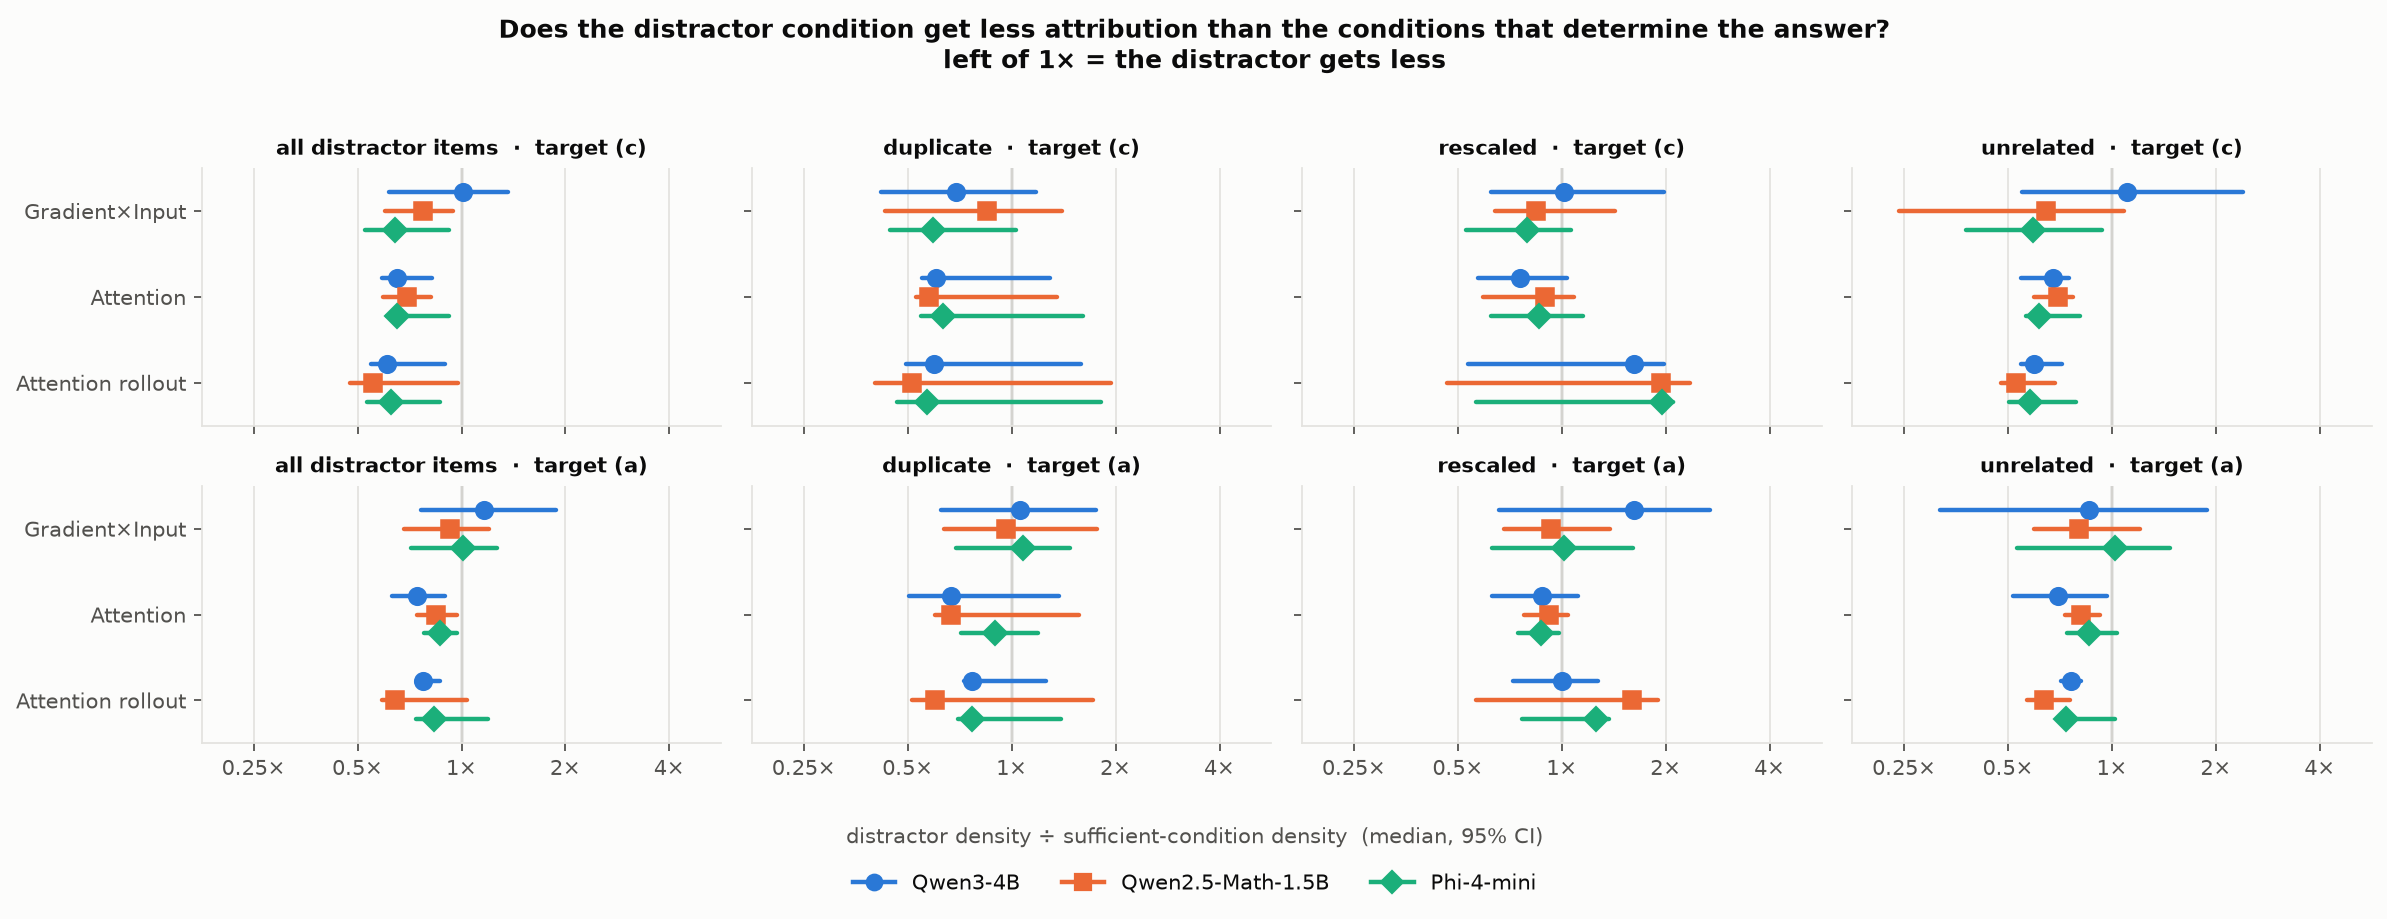

Qwen3-4B  Qwen2.5-Math-1.5B  \
target subtype   method                                                    
c      all       Gradient×Input     1.01 [0.62, 1.37]  0.78 [0.60, 0.94]   
                 Attention          0.65 [0.59, 0.82]  0.69 [0.59, 0.82]   
                 Attention rollout  0.61 [0.55, 0.89]  0.55 [0.47, 0.98]   
       duplicate Gradient×Input     0.69 [0.42, 1.18]  0.85 [0.43, 1.40]   
                 Attention          0.60 [0.55, 1.29]  0.58 [0.53, 1.35]   
                 Attention rollout  0.59 [0.50, 1.59]  0.52 [0.40, 1.94]   
       rescaled  Gradient×Input     1.01 [0.63, 1.98]  0.84 [0.64, 1.43]   
                 Attention          0.75 [0.57, 1.04]  0.89 [0.59, 1.09]   
                 Attention rollout  1.61 [0.53, 1.97]  1.94 [0.47, 2.36]   
       unrelated Gradient×Input     1.11 [0.55, 2.39]  0.64 [0.24, 1.08]   
                 Attention          0.68 [0.55, 0.75]  0.70 [0.59, 0.77]   
                 Attention rollout  0.59 [0.55, 0.72]  0.53 [0.48, 0.68]   
a      all       Gradient×Input     1.16 [0.76, 1.88]  0.93 [0.68, 1.20]   
                 Attention          0.74 [0.63, 0.90]  0.84 [0.74, 0.97]   
                 Attention rollout  0.77 [0.75, 0.87]  0.64 [0.59, 1.04]   
       duplicate Gradient×Input     1.05 [0.63, 1.75]  0.96 [0.64, 1.77]   
                 Attention          0.67 [0.51, 1.37]  0.67 [0.60, 1.57]   
                 Attention rollout  0.77 [0.73, 1.26]  0.60 [0.51, 1.71]   
       rescaled  Gradient×Input     1.61 [0.66, 2.69]  0.93 [0.68, 1.38]   
                 Attention          0.88 [0.63, 1.12]  0.92 [0.77, 1.04]   
                 Attention rollout  1.00 [0.72, 1.27]  1.60 [0.56, 1.90]   
       unrelated Gradient×Input     0.86 [0.32, 1.89]  0.80 [0.59, 1.20]   
                 Attention          0.70 [0.52, 0.97]  0.81 [0.73, 0.92]   
                 Attention rollout  0.76 [0.71, 0.81]  0.64 [0.57, 0.76]   

                                           Phi-4-mini  
target subtype   method                                
c      all       Gradient×Input     0.64 [0.52, 0.92]  
                 Attention          0.65 [0.61, 0.92]  
                 Attention rollout  0.63 [0.53, 0.87]  
       duplicate Gradient×Input     0.59 [0.44, 1.03]  
                 Attention          0.63 [0.55, 1.61]  
                 Attention rollout  0.57 [0.47, 1.81]  
       rescaled  Gradient×Input     0.79 [0.53, 1.06]  
                 Attention          0.86 [0.62, 1.15]  
                 Attention rollout  1.95 [0.56, 2.10]  
       unrelated Gradient×Input     0.59 [0.38, 0.93]  
                 Attention          0.61 [0.56, 0.81]  
                 Attention rollout  0.58 [0.50, 0.79]  
a      all       Gradient×Input     1.01 [0.71, 1.27]  
                 Attention          0.87 [0.78, 0.97]  
                 Attention rollout  0.83 [0.74, 1.19]  
       duplicate Gradient×Input     1.08 [0.69, 1.47]  
                 Attention          0.89 [0.72, 1.19]  
                 Attention rollout  0.77 [0.70, 1.39]  
       rescaled  Gradient×Input     1.01 [0.63, 1.61]  
                 Attention          0.87 [0.74, 0.98]  
                 Attention rollout  1.25 [0.76, 1.37]  
       unrelated Gradient×Input     1.02 [0.53, 1.47]  
                 Attention          0.86 [0.74, 1.04]  
                 Attention rollout  0.74 [0.69, 1.02]

In [6]:
show('2_distractor.png')
tab = []
for t in ('c', 'a'):
    for sub in ('all', 'duplicate', 'rescaled', 'unrelated'):
        for meth in MAIN:
            tab.append({'target': t, 'subtype': sub, 'method': AP.METHOD_LABEL[meth],
                        **{ML[mk]: fmt(stats.get(f'{t} | distr/suff {sub} | {mk} | {meth}'), log2=True) for mk in MODELS}})
pd.DataFrame(tab).set_index(['target', 'subtype', 'method'])

**Reading.**
- **`unrelated`** gives the clearest effect: attention 0.61–0.70× in (c), with every interval below 1. A condition
  on z is easy to tell apart from a condition on y.
- **`rescaled`** gives the weakest effect: 0.75–0.89×, with intervals reaching 1. A rescaled condition looks like a
  real condition on y, so the models seem to treat it almost like a useful one.
- The intervals per subtype are wide for Gradient×Input (36 items per panel).

## 4. Repeated condition: a position effect

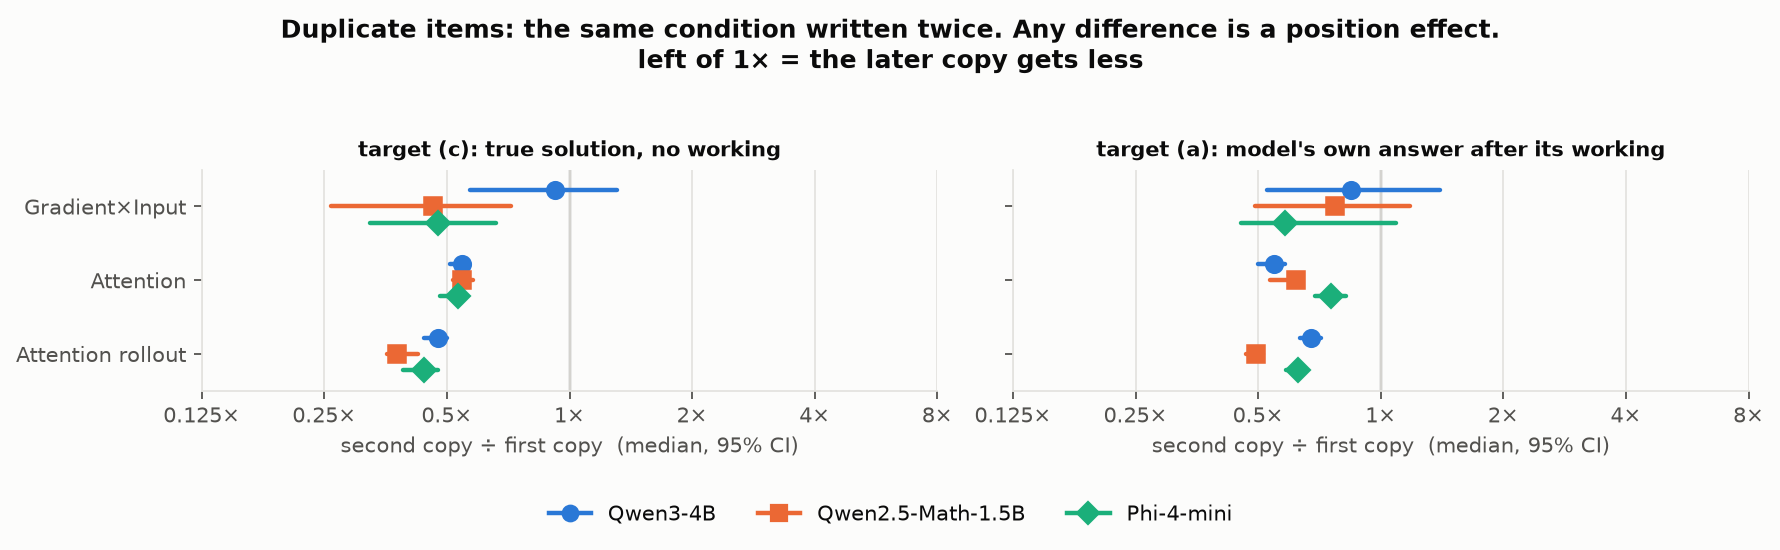

Qwen3-4B  Qwen2.5-Math-1.5B  \
target method                                                    
c      Gradient×Input     0.92 [0.57, 1.31]  0.46 [0.26, 0.72]   
       Attention          0.54 [0.51, 0.57]  0.55 [0.52, 0.58]   
       Attention rollout  0.48 [0.44, 0.50]  0.38 [0.36, 0.42]   
a      Gradient×Input     0.84 [0.53, 1.40]  0.77 [0.49, 1.18]   
       Attention          0.55 [0.50, 0.58]  0.62 [0.54, 0.64]   
       Attention rollout  0.67 [0.63, 0.71]  0.49 [0.47, 0.51]   

                                 Phi-4-mini  
target method                                
c      Gradient×Input     0.48 [0.32, 0.66]  
       Attention          0.53 [0.48, 0.56]  
       Attention rollout  0.44 [0.39, 0.48]  
a      Gradient×Input     0.58 [0.45, 1.09]  
       Attention          0.75 [0.69, 0.82]  
       Attention rollout  0.63 [0.58, 0.65]

In [7]:
show('3_duplicate_position.png', width=900)
pd.DataFrame([{'target': t, 'method': AP.METHOD_LABEL[meth],
               **{ML[mk]: fmt(stats.get(f'{t} | dup 2nd/1st | {mk} | {meth}'), log2=True) for mk in MODELS}}
              for t in ('c', 'a') for meth in MAIN]).set_index(['target', 'method'])

**Reading.** The two copies are identical text, so any difference is due only to **position**. All three models
attend mainly to the **first** copy (second ≈ 0.53–0.75× of the first). By Gradient×Input, Qwen2.5-Math and Phi also
rely mainly on the first copy in (c); Qwen3-4B uses both copies about equally.

## 5. Layer by layer
Attention from the answer tokens to the equation, the sufficient conditions and the distractor, in each layer.

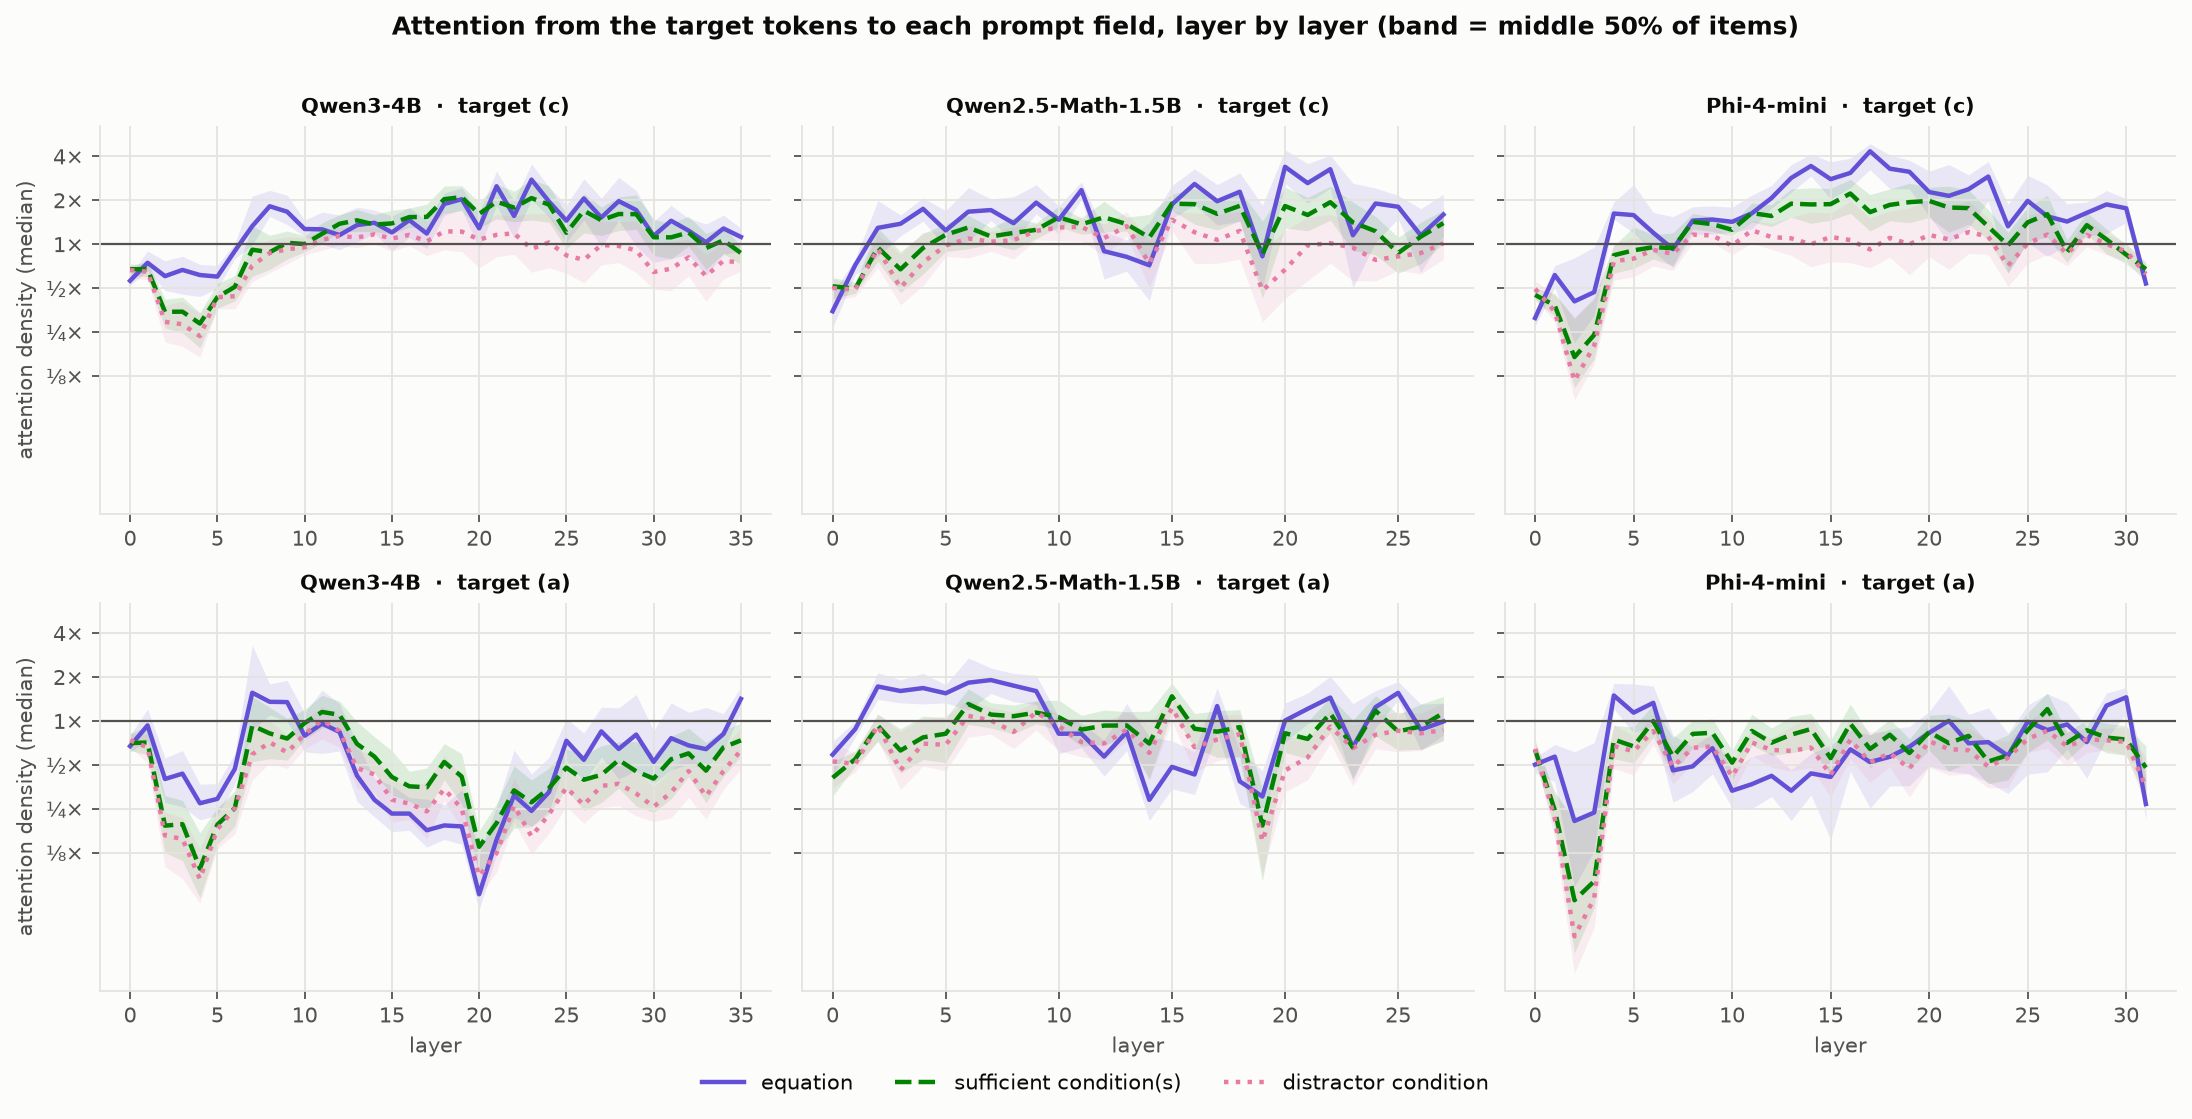

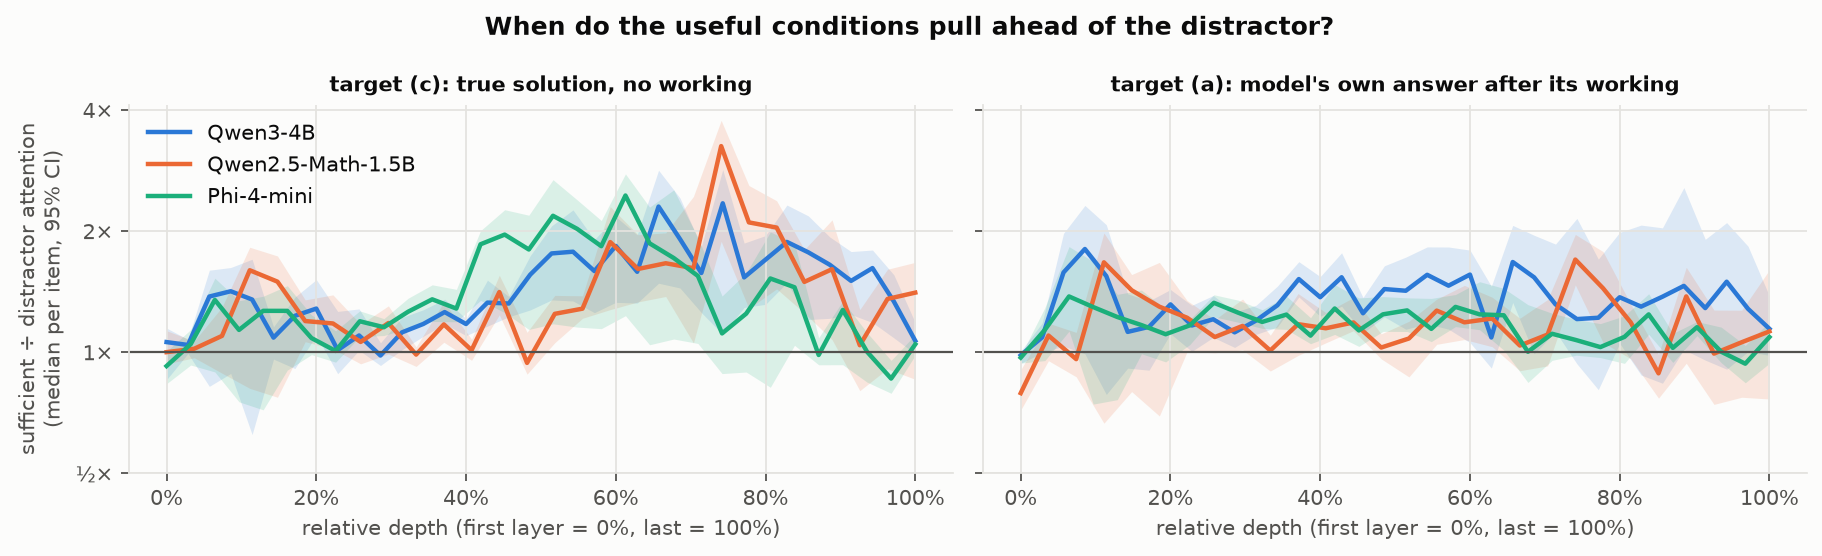

layers  peak layer (from 0) peak relative depth  \
target model                                                                
c      Qwen3-4B               36                   26                 74%   
       Qwen2.5-Math-1.5B      28                   20                 74%   
       Phi-4-mini             32                   19                 61%   
a      Qwen3-4B               36                    3                  9%   
       Qwen2.5-Math-1.5B      28                   20                 74%   
       Phi-4-mini             32                    2                  6%   

                         peak ratio layers with CI above 1×  
target model                                                 
c      Qwen3-4B                2.34                26 of 36  
       Qwen2.5-Math-1.5B       3.25                15 of 28  
       Phi-4-mini              2.45                16 of 32  
a      Qwen3-4B                1.80                21 of 36  
       Qwen2.5-Math-1.5B       1.70                 9 of 28  
       Phi-4-mini              1.38                17 of 32

In [8]:
show('4_attention_layers.png')

# cross-model view: per-item log2(sufficient ÷ distractor) per layer, on relative depth so the models align
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5), sharey=True)
peaks = []
for ax, t in zip(axes, ('c', 'a')):
    for mk in MODELS:
        run = runs.get((mk, t))
        L = [x for x in (AP.layer_densities(r) for r in run['rows']) if x and not math.isnan(x['distractor'][0])]
        R = np.log2(np.array([x['sufficient'] for x in L]) / np.array([x['distractor'] for x in L]))
        nl = R.shape[1]
        med = np.median(R, axis=0)
        boot = np.median(R[AP.RNG.integers(0, len(R), (1000, len(R)))], axis=1)
        lo, hi = np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
        depth = np.arange(nl) / (nl - 1)
        c = AP.MODEL_COLOR[mk]
        ax.fill_between(depth, 2 ** lo, 2 ** hi, color=c, alpha=0.15, lw=0)
        ax.plot(depth, 2 ** med, color=c, label=ML[mk])
        k = int(np.argmax(med))
        peaks.append({'target': t, 'model': ML[mk], 'layers': nl, 'peak layer (from 0)': k,
                      'peak relative depth': f'{k / (nl - 1):.0%}', 'peak ratio': f'{2 ** med[k]:.2f}',
                      'layers with CI above 1×': f'{int(np.sum(lo > 0))} of {nl}'})
    ax.axhline(1, color=AP.INK2, lw=1)
    ax.set_yscale('log', base=2)
    ax.set_yticks([0.5, 1, 2, 4]); ax.set_yticklabels(['½×', '1×', '2×', '4×'])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_xlabel('relative depth (first layer = 0%, last = 100%)')
    ax.set_title(AP.TARGET_LABEL[t], fontsize=9.5)
axes[0].set_ylabel('sufficient ÷ distractor attention\n(median per item, 95% CI)')
axes[0].legend(loc='upper left')
fig.suptitle('When do the useful conditions pull ahead of the distractor?', fontweight='bold')
fig.tight_layout()
fig.savefig(os.path.join(FIG, '4b_layer_separation_depth.png'), dpi=160, bbox_inches='tight')
plt.close(fig)
show('4b_layer_separation_depth.png')
pd.DataFrame(peaks).set_index(['target', 'model'])

**Reading.**
- In the first few layers all prompt fields are below proportion and the useful conditions and the distractor
  are treated alike.
- **Target (c):** the useful conditions pull ahead of the distractor **in the middle-to-upper part of every
  model**, at about 40–85% depth, with the peak at 60–75% depth (up to 2.3–3.3×).
- **Target (a):** after the model's own working the separation is **smaller and flatter**: about 1.2–1.6× across
  most layers, with no clear peak (the "peak layer" in the table is just the noisiest maximum).
- The 40–85% depth range is where probes for "condition role" should look first.

## 6. Target (a): how much of the answer comes from the model's own working

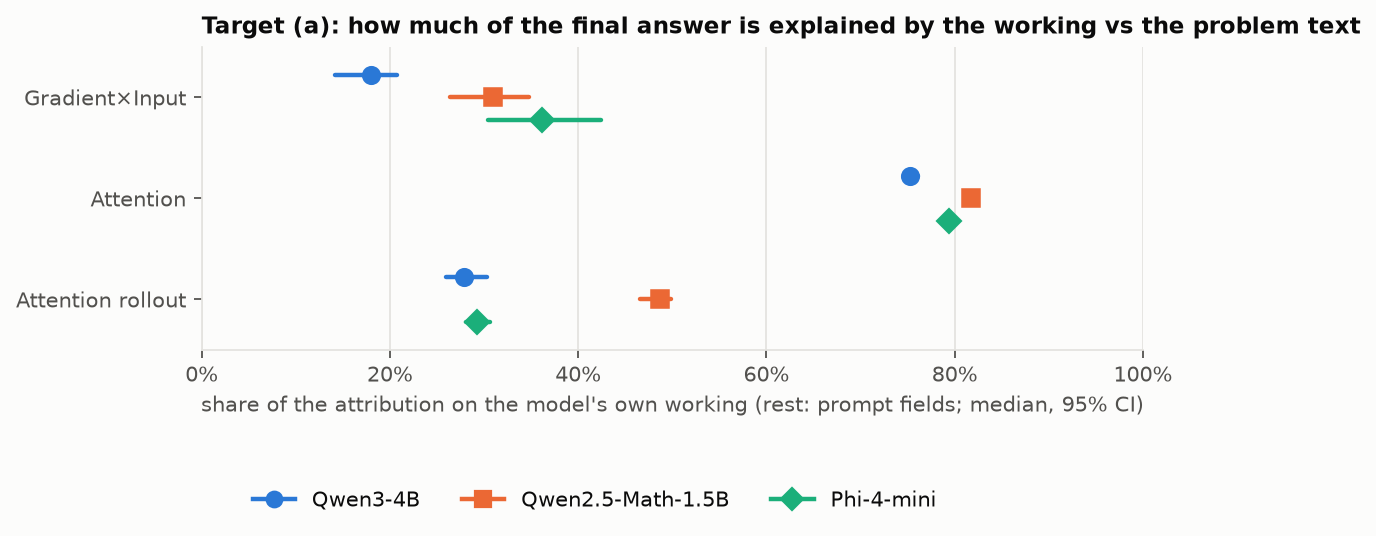

,Qwen3-4B,Qwen2.5-Math-1.5B,Phi-4-mini
method,,,
Gradient×Input,"18% [14%, 21%]","31% [26%, 35%]","36% [30%, 42%]"
Attention,"75% [75%, 76%]","82% [81%, 82%]","79% [79%, 80%]"
Attention rollout,"28% [26%, 30%]","49% [47%, 50%]","29% [28%, 31%]"


In [9]:
show('5_working_share.png', width=750)
pd.DataFrame([{'method': AP.METHOD_LABEL[meth],
               **{ML[mk]: (lambda s: f"{s['median']:.0%} [{s['lo']:.0%}, {s['hi']:.0%}]")(stats[f'a | working share | {mk} | {meth}'])
                  for mk in MODELS}} for meth in MAIN]).set_index('method')

**Reading.** A large part of the final answer is explained by the model's own working: 18–36% by Gradient×Input
and 75–82% by attention. The size depends a lot on the method; the conclusion that the working matters doesn't.
Explanations that look only at the problem text miss a large part of the process. This motivates analysing the
hidden states of the working as well, not just of the prompt.

## 7. Correct vs wrong answers
Only runs with at least 10 wrong answers. Dots = correct, crosses = wrong.

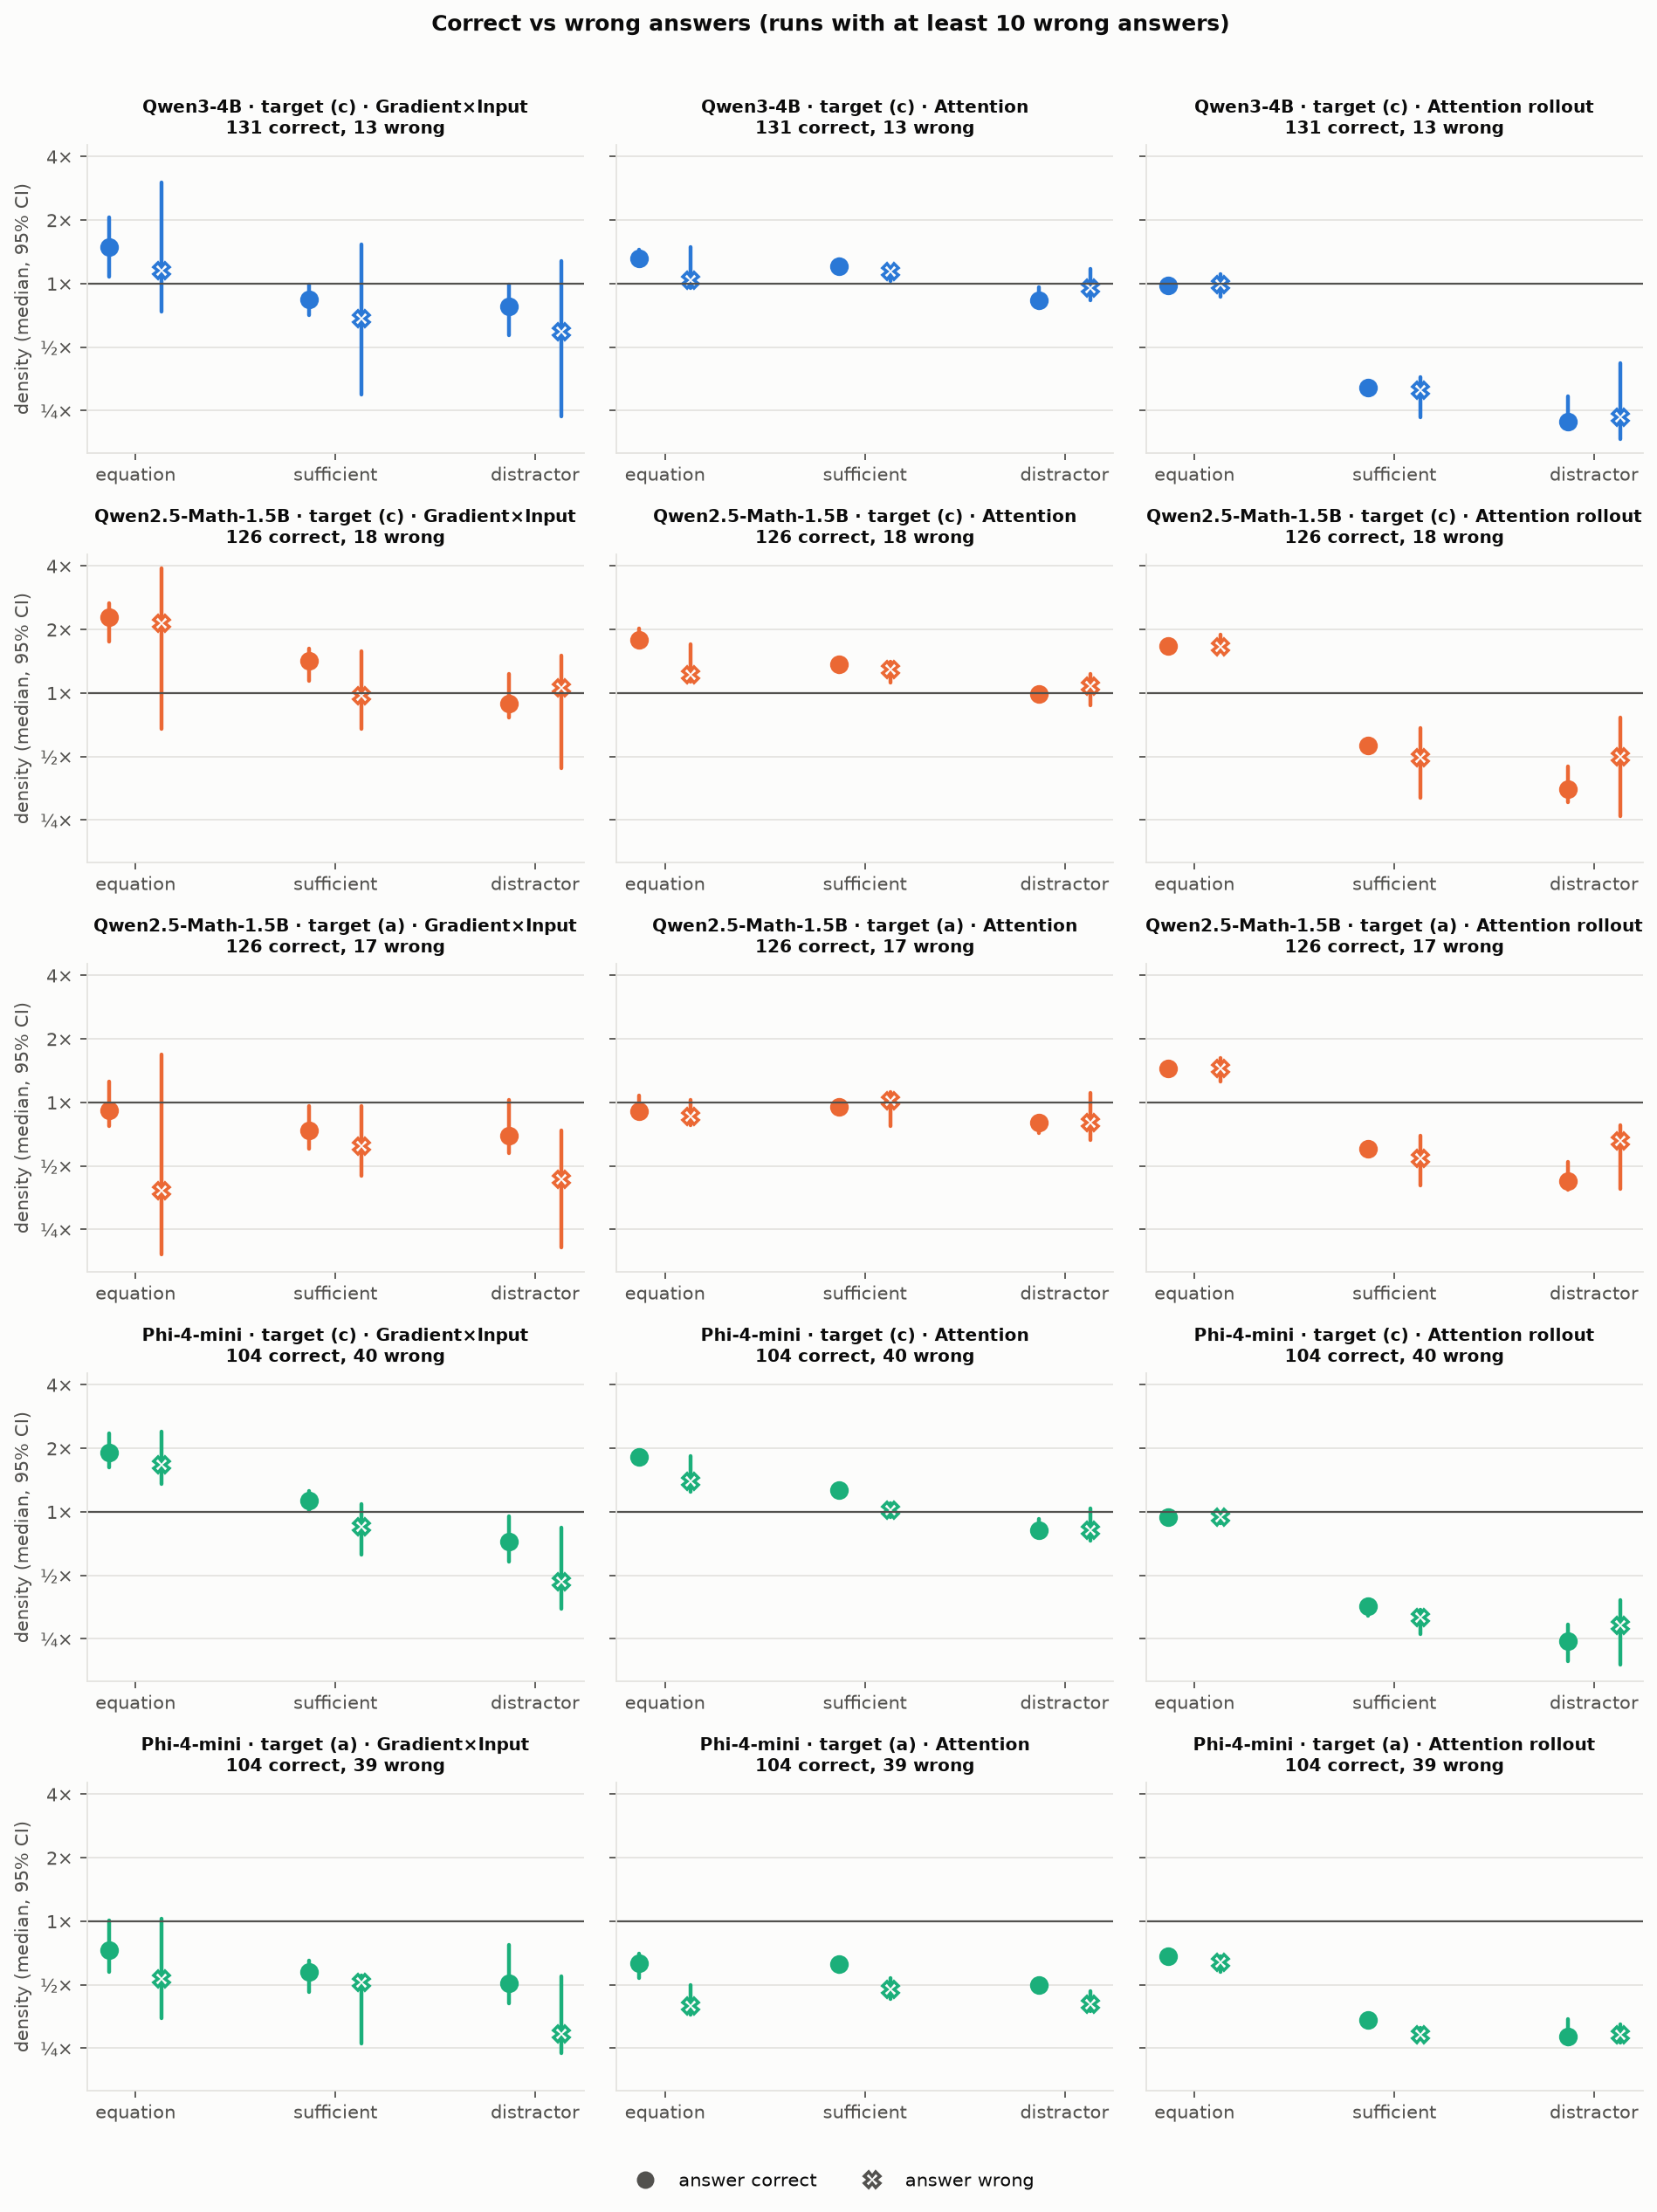

correct  \
model             target wrong method         field                           
Qwen3-4B          c      13    Gradient×Input equation    1.50 [1.08, 2.05]   
                                              sufficient  0.84 [0.71, 0.99]   
                                              distractor  0.78 [0.57, 0.99]   
                               Attention      equation    1.32 [1.28, 1.45]   
                                              sufficient  1.21 [1.14, 1.31]   
                                              distractor  0.83 [0.76, 0.96]   
Qwen2.5-Math-1.5B a      17    Gradient×Input equation    0.92 [0.77, 1.26]   
                                              sufficient  0.74 [0.60, 0.96]   
                                              distractor  0.70 [0.57, 1.03]   
                               Attention      equation    0.91 [0.85, 1.08]   
                                              sufficient  0.95 [0.90, 1.02]   
                                              distractor  0.80 [0.71, 0.83]   
                  c      18    Gradient×Input equation    2.28 [1.76, 2.67]   
                                              sufficient  1.42 [1.14, 1.62]   
                                              distractor  0.89 [0.77, 1.24]   
                               Attention      equation    1.78 [1.66, 2.02]   
                                              sufficient  1.37 [1.26, 1.44]   
                                              distractor  0.99 [0.95, 1.06]   
Phi-4-mini        a      39    Gradient×Input equation    0.73 [0.58, 1.01]   
                                              sufficient  0.57 [0.46, 0.65]   
                                              distractor  0.51 [0.41, 0.77]   
                               Attention      equation    0.63 [0.54, 0.70]   
                                              sufficient  0.63 [0.58, 0.67]   
                                              distractor  0.50 [0.47, 0.53]   
                  c      40    Gradient×Input equation    1.92 [1.62, 2.34]   
                                              sufficient  1.13 [1.01, 1.26]   
                                              distractor  0.72 [0.58, 0.95]   
                               Attention      equation    1.82 [1.70, 1.88]   
                                              sufficient  1.27 [1.17, 1.32]   
                                              distractor  0.82 [0.76, 0.92]   

                                                                     wrong   
model             target wrong method         field                          
Qwen3-4B          c      13    Gradient×Input equation    1.15 [0.74, 3.02]  
                                              sufficient  0.68 [0.30, 1.53]  
                                              distractor  0.59 [0.23, 1.28]  
                               Attention      equation    1.04 [0.95, 1.50]  
                                              sufficient  1.14 [1.03, 1.16]  
                                              distractor  0.95 [0.83, 1.18]  
Qwen2.5-Math-1.5B a      17    Gradient×Input equation    0.38 [0.19, 1.69]  
                                              sufficient  0.62 [0.45, 0.96]  
                                              distractor  0.43 [0.20, 0.74]  
                               Attention      equation    0.86 [0.78, 1.03]  
                                              sufficient  1.02 [0.77, 1.12]  
                                              distractor  0.80 [0.66, 1.11]  
                  c      18    Gradient×Input equation    2.15 [0.68, 3.89]  
                                              sufficient  0.97 [0.67, 1.58]  
                                              distractor  1.06 [0.44, 1.50]  
                               Attention      equation    1.22 [1.13, 1.71]  
                                              sufficient  1.29 [1.12, 1.40]  
                                              distractor 

In [10]:
show('6_correct_vs_wrong.png')
tab = []
for (mk, t), run in sorted(runs.items(), key=lambda kv: (AP.MODEL_ORDER.index(kv[0][0]), kv[0][1])):
    nw = sum(1 for x in run['rows'] if x.get('correct') is False)
    if nw < 10:
        continue
    for meth in ('gxi', 'attn'):
        for f in ('equation', 'sufficient', 'distractor'):
            tab.append({'model': ML[mk], 'target': t, 'wrong': nw, 'method': AP.METHOD_LABEL[meth], 'field': f,
                        'correct': fmt(stats.get(f'{t} | {mk} | {meth} | {f} | correct')),
                        'wrong ': fmt(stats.get(f'{t} | {mk} | {meth} | {f} | wrong'))})
pd.DataFrame(tab).set_index(['model', 'target', 'wrong', 'method', 'field'])

**Reading.**
- Wrong answers go with **less weight on the equation and on the useful conditions**. This is clearest for Phi
  (about 40 wrong answers, mostly non-overlapping intervals), and in the same direction for Qwen2.5-Math (18 wrong)
  and Qwen3-4B (13 wrong).
- It appears **in target (c) too**, where the scored answer is the true one. So it reflects how the model reads
  those problems, not just its wrong output.
- The samples of wrong answers are small, so this is suggestive. The representation analysis can test it on all
  792 items: can the field representations predict whether the answer will be correct?

## Appendix A. Why Integrated Gradients is not used
IG adds up gradients along a path from a *baseline* input to the real one. It was computed with two baselines
(pad-token embedding and all-zero embedding). Following the user's decision of 2026-11-04 it is reported for
completeness only, for three reasons:
1. **The path runs through inputs that are not problems.** The points between the baseline and the input are not
   valid ODE problems. This is a weaker form of the objection that rules out LIME, SHAP and occlusion here.
2. **There is no natural baseline for an ODE problem, and the two baselines disagree** (figure below): they rank
   the fields almost independently and pick the same top field only about as often as chance.
3. **It did not converge** within a practical number of steps: the attributions don't add up to the change in the
   output, by 4–31% with the pad baseline and 60–1160% with the zero baseline.

Point 3 alone is a numerical issue (more steps would close the gap); the argument rests on 1 and 2.
Gradient×Input is a gradient at the real input, with no path and no baseline, so it doesn't share these problems.

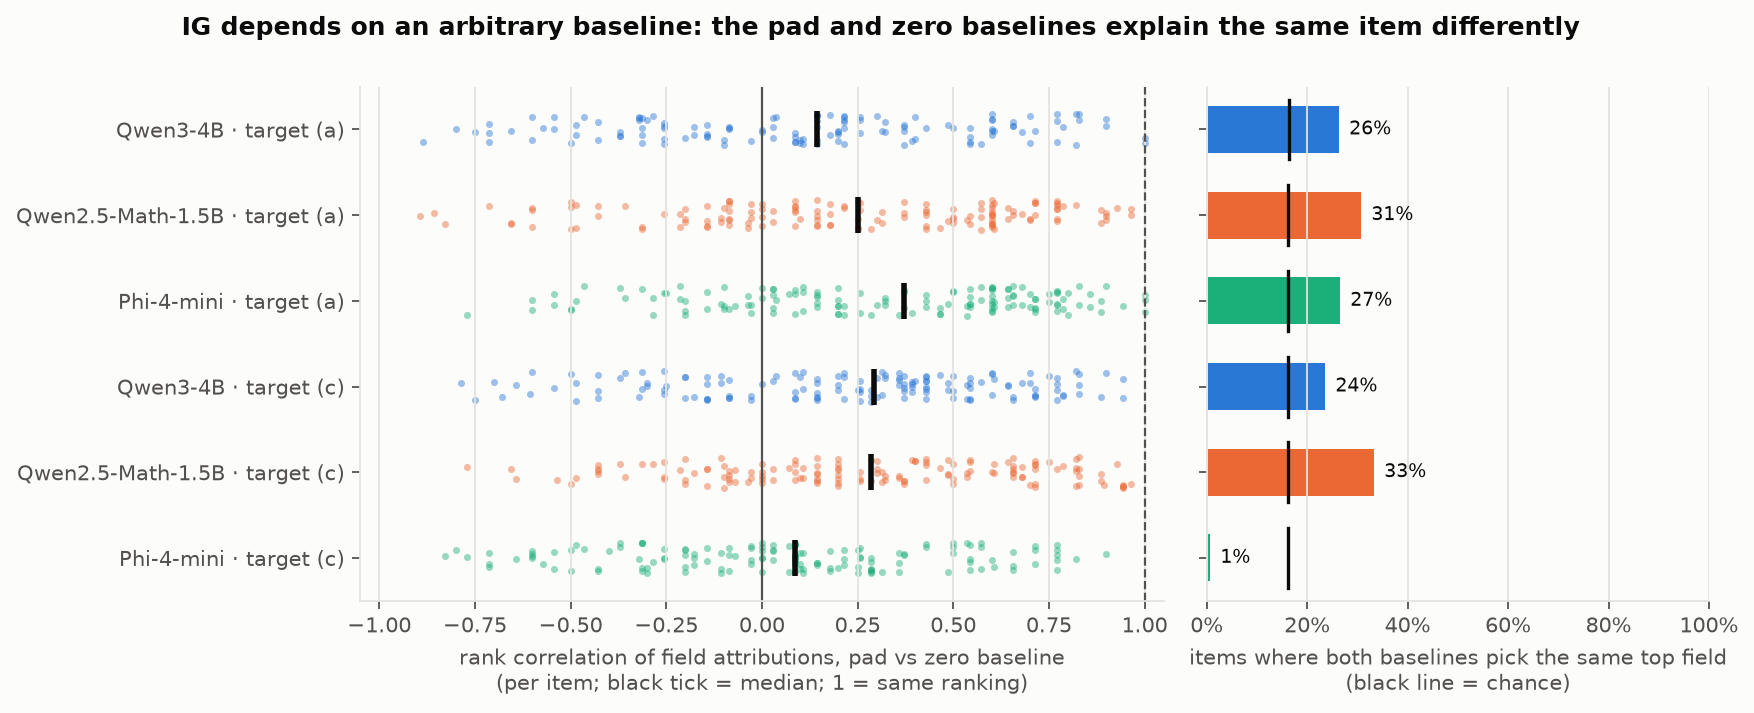

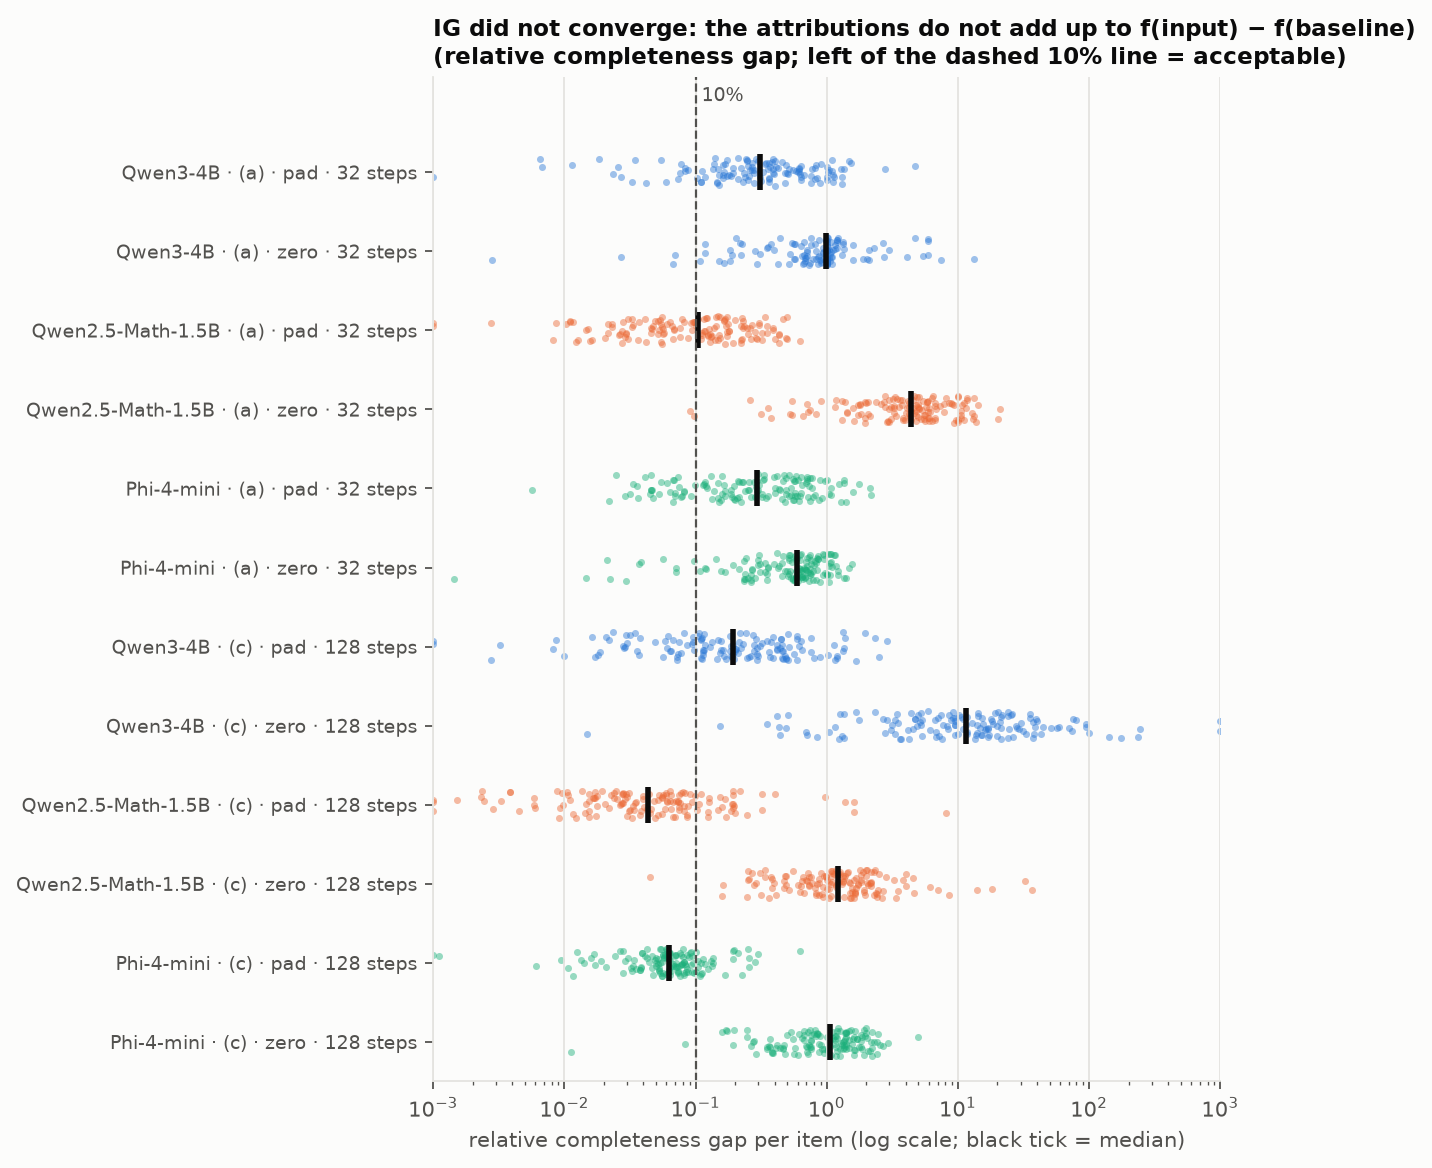

,IG steps,"gap, pad (median)","gap, zero (median)",pad vs zero rank corr. (median),same top field
run,,,,,
Qwen3-4B · target (a),32,31%,99%,0.14,26% (chance 16%)
Qwen2.5-Math-1.5B · target (a),32,10%,441%,0.25,31% (chance 16%)
Phi-4-mini · target (a),32,30%,60%,0.37,27% (chance 16%)
Qwen3-4B · target (c),128,19%,1160%,0.29,24% (chance 16%)
Qwen2.5-Math-1.5B · target (c),128,4%,122%,0.29,33% (chance 16%)
Phi-4-mini · target (c),128,6%,106%,0.09,1% (chance 16%)


In [11]:
show('8_ig_baselines.png')
show('7_ig_completeness.png', width=800)
ig = []
for r in sorted(RUNS, key=lambda r: (r['target'], AP.MODEL_ORDER.index(r['model']))):
    lab = f"{ML[r['model']]} · target ({r['target']})"
    b = stats[f'ig baselines | {lab}']
    g = {k: np.array(v) for k, v in r['gaps'].items()}
    ig.append({'run': lab, 'IG steps': r['meta']['ig_steps'],
               'gap, pad (median)': f"{np.median(g['ig_pad']):.0%}", 'gap, zero (median)': f"{np.median(g['ig_mask']):.0%}",
               'pad vs zero rank corr. (median)': f"{b['spearman_median']:.2f}",
               'same top field': f"{b['top_field_agree']:.0%} (chance {b['chance']:.0%})"})
pd.DataFrame(ig).set_index('run')

## Appendix B. Caveats
- **Sample size:** 144 items per model and target (2 per category × subtype); 36 per subtype; 13–40 wrong answers.
- **Gradient×Input saturation:** 13 of 129 Qwen3-4B (a) items have log p(answer) = 0 (the model is certain of an
  answer it already wrote in its working), so the gradient is zero and they drop out of the Gradient×Input numbers.
- **Attention is averaged** over heads (and over layers in the field tables); single heads can behave differently.
- **Rollout** has an early-token bias; read it as weak evidence.
- **Precision:** Qwen2.5-Math ran in fp32 (fp16 overflowed in eager attention), the others in fp16. The measures
  are ratios within an item, so this shouldn't bias the comparisons.

## Appendix C. Questions for the representation analysis
1. Is the distractor **encoded** differently from the useful conditions (a linear probe for condition role, per
   layer)? The attention result predicts separation at 40–85% depth, and (section 1b) only when the distractor
   comes after a useful condition.
2. Is a **rescaled** condition represented more like a useful condition than the unrelated z-condition is?
3. Are the two identical copies in **duplicate** items represented the same way, layer by layer?
4. Does Qwen2.5-Math's stronger focus on the equation show up as a **different geometry** (RSA / CKA across
   models)?
5. Can the field representations **predict a wrong answer**?